In [4]:
import polars as pl
import matplotlib.pyplot as plt

df = pl.read_csv("../chicago-ward-income.csv")

df.head()

ward,acs_year,households_under_25k,households_25k_to_50k,households_50k_to_75k,households_75k_to_125k,households_125k_plus,households_total,pct_households_125k_plus,median_household_income_est
i64,i64,i64,i64,i64,i64,i64,i64,f64,i64
1,2023,721,943,760,1721,6677,10822,61.7,148701
2,2023,482,627,613,1250,7494,10466,71.6,162714
3,2023,1820,1545,994,1772,4431,10562,42.0,101016
4,2023,1728,1288,950,1639,4573,10178,44.9,109259
5,2023,1584,1359,1134,1665,2861,8603,33.3,81742


In [6]:
# Part1
print("Dataset Shape:")
print(df.shape)

print("\nDataset Schema:")
df.glimpse()

print("\nMissing Values:")
print(df.null_count())

print("\nDescriptive Statistics:")
print(df.describe())

Dataset Shape:
(50, 10)

Dataset Schema:
Rows: 50
Columns: 10
$ ward                        <i64> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10
$ acs_year                    <i64> 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023, 2023
$ households_under_25k        <i64> 721, 482, 1820, 1728, 1584, 2504, 2044, 2120, 2647, 2330
$ households_25k_to_50k       <i64> 943, 627, 1545, 1288, 1359, 2407, 2034, 2031, 2477, 2925
$ households_50k_to_75k       <i64> 760, 613, 994, 950, 1134, 1468, 1250, 1940, 1609, 2347
$ households_75k_to_125k      <i64> 1721, 1250, 1772, 1639, 1665, 1779, 1677, 2447, 2733, 2963
$ households_125k_plus        <i64> 6677, 7494, 4431, 4573, 2861, 1505, 1609, 2326, 1396, 2172
$ households_total            <i64> 10822, 10466, 10562, 10178, 8603, 9663, 8614, 10864, 10862, 12737
$ pct_households_125k_plus    <f64> 61.7, 71.6, 42.0, 44.9, 33.3, 15.6, 18.7, 21.4, 12.9, 17.1
$ median_household_income_est <i64> 148701, 162714, 101016, 109259, 81742, 49174, 54580, 66508, 54770, 61861


Mi

### Part 1: Dataset Profiling:Chicago Ward Income

The Chicago ward income dataset contains 50 rows and 10 columns, representing the 50 wards in Chicago. All observations are from 2023.

The dataset includes household counts for different income categories, total households, the percentage of households earning $125,000 or more, and estimated median household income.

All columns were read as integer values, which is appropriate for the numerical variables in this dataset. The ward column serves as a geographic identifier rather than a numerical measurement.

Overall, this dataset provides useful information about economic differences between Chicago wards, which could help us explore whether income levels are associated with crime patterns.

In [7]:
#Part 2
print("Missing Values:")
print(df.null_count())

print("\nDuplicate Rows:")
print(df.is_duplicated().sum())

print("\nDuplicate Ward Numbers:")
print(df["ward"].is_duplicated().sum())

print("\nInvalid Ward Numbers:")
print(df.filter(~pl.col("ward").is_between(1, 50)).height)

print("\nNegative Household Counts:")
household_cols = [
    "households_under_25k",
    "households_25k_to_50k",
    "households_50k_to_75k",
    "households_75k_to_125k",
    "households_125k_plus",
    "households_total"
]

for col in household_cols:
    print(col, df.filter(pl.col(col) < 0).height)

print("\nInvalid Income Values:")
print(
    df.filter(
        pl.col("median_household_income_est") < 0
    ).height
)

print("\nInvalid Percentage Values:")
print(
    df.filter(
        ~pl.col("pct_households_125k_plus").is_between(0, 100)
    ).height
)

print("\nHousehold Total Inconsistencies:")
df = df.with_columns(
    pl.sum_horizontal(household_cols[:-1]).alias("calculated_total")
)

print(
    df.filter(
        pl.col("calculated_total") != pl.col("households_total")
    ).height
)

Missing Values:
shape: (1, 10)
┌──────┬──────────┬────────────────┬───────────────┬───┬───────────────┬───────────────┬───────────────┬───────────────┐
│ ward ┆ acs_year ┆ households_und ┆ households_25 ┆ … ┆ households_12 ┆ households_to ┆ pct_household ┆ median_househ │
│ ---  ┆ ---      ┆ er_25k         ┆ k_to_50k      ┆   ┆ 5k_plus       ┆ tal           ┆ s_125k_plus   ┆ old_income_es │
│ u32  ┆ u32      ┆ ---            ┆ ---           ┆   ┆ ---           ┆ ---           ┆ ---           ┆ t             │
│      ┆          ┆ u32            ┆ u32           ┆   ┆ u32           ┆ u32           ┆ u32           ┆ ---           │
│      ┆          ┆                ┆               ┆   ┆               ┆               ┆               ┆ u32           │
╞══════╪══════════╪════════════════╪═══════════════╪═══╪═══════════════╪═══════════════╪═══════════════╪═══════════════╡
│ 0    ┆ 0        ┆ 0              ┆ 0             ┆ … ┆ 0             ┆ 0             ┆ 0             ┆ 0             │
└

### Part 2: Anomaly Detection:Chicago Ward Income

I checked the dataset for missing values, duplicate records, invalid ward numbers, negative household counts, and incorrect income or percentage values.

The results showed no missing values or duplicate records. All ward numbers were within the valid range of 1 to 50, and there were no negative household counts or median household income values.

I also checked whether the household counts across income categories matched the reported total households. No inconsistencies were found.

Overall, no anomalies were identified in these checks, so no rows were removed or modified. The original data was kept for further analysis.

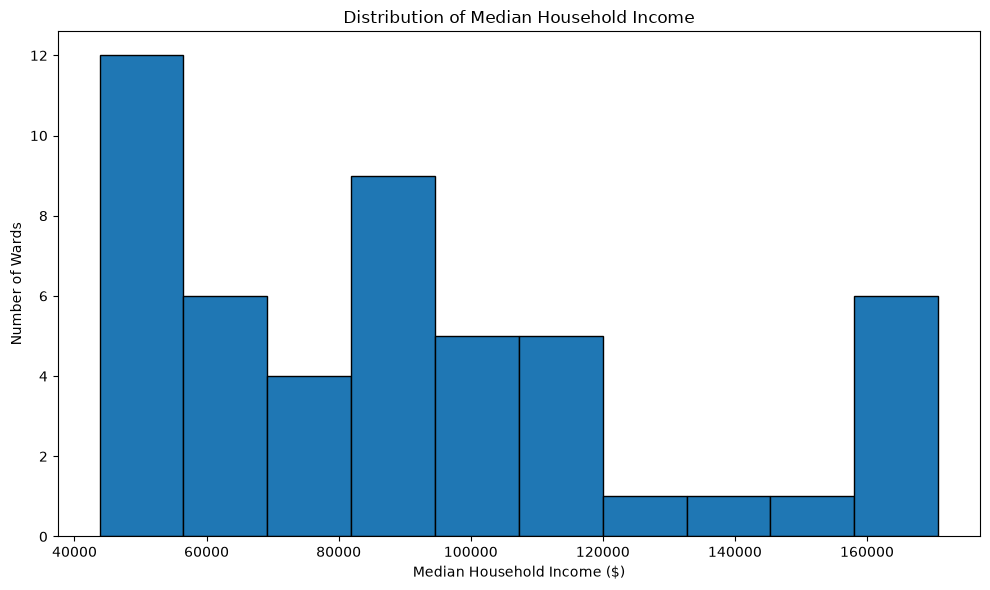

In [8]:
# Part 3
plt.figure(figsize=(10, 6))

plt.hist(
    df["median_household_income_est"].to_numpy(),
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of Median Household Income")
plt.xlabel("Median Household Income ($)")
plt.ylabel("Number of Wards")

plt.tight_layout()
plt.show()

### Plot 1: Distribution of Median Household Income

The histogram shows that median household income varies considerably across Chicago's 50 wards. Most wards have median household incomes between approximately $45,000 and $120,000, while a smaller number have incomes above $150,000.

The average estimated median household income is around $91,103. The distribution appears somewhat right-skewed, with a few wards having much higher incomes than the others.

This suggests that there are noticeable economic differences across Chicago wards, which could be useful when studying how crime patterns vary between areas.

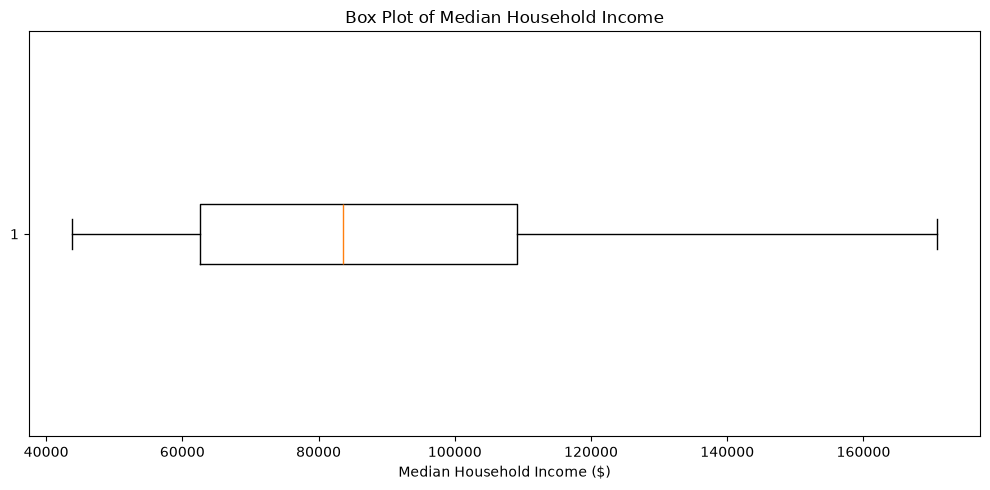

In [10]:
plt.figure(figsize=(10, 5))

plt.boxplot(
    df["median_household_income_est"].to_numpy(),
    orientation="horizontal"
)

plt.title("Box Plot of Median Household Income")
plt.xlabel("Median Household Income ($)")

plt.tight_layout()
plt.show()

### Plot 2: Box Plot of Median Household Income

The box plot shows that the median household income across Chicago wards is approximately 83,000 dollars. The middle 50% of wards have median household incomes between roughly 63,000 and 109,000 dollars.

The income values range from approximately 44,000 to 171,000 dollars, showing a considerable difference between the lowest-income and highest-income wards.

The upper whisker is longer than the lower whisker, suggesting that incomes are more spread out toward the higher end. No statistical outliers were identified by the box plot.

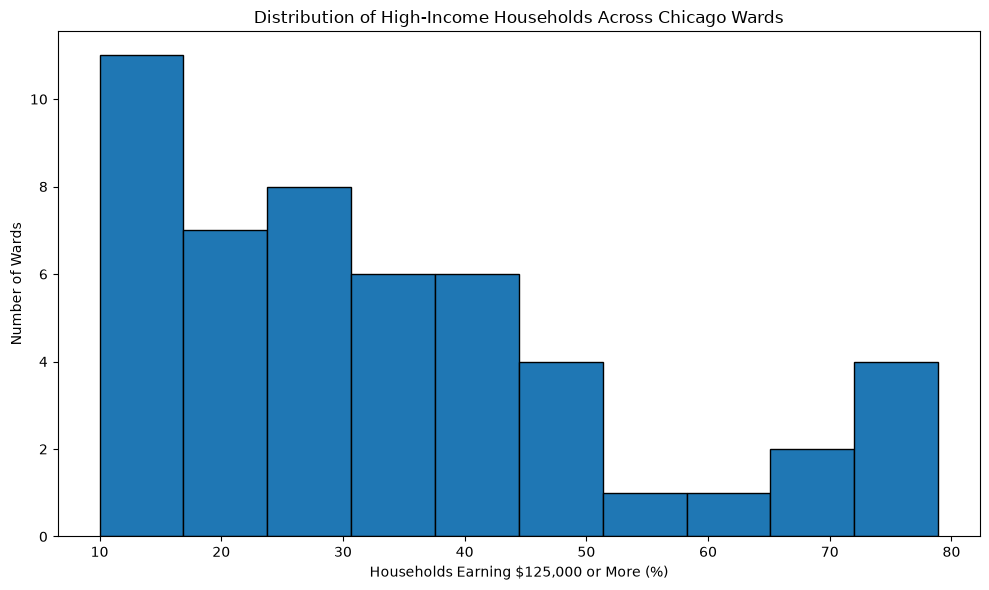

In [11]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["pct_households_125k_plus"].to_numpy(),
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of High-Income Households Across Chicago Wards")
plt.xlabel("Households Earning $125,000 or More (%)")
plt.ylabel("Number of Wards")

plt.tight_layout()
plt.show()

### Plot 3: Distribution of High-Income Households

The histogram shows that the percentage of households earning 125,000 dollars or more varies considerably across Chicago's 50 wards.

Most wards have approximately 10% to 45% of households in this income category, while a few wards have percentages above 70%.

The average percentage is approximately 34.4%. The distribution is right-skewed, with most wards concentrated at lower percentages and fewer wards having very high percentages.

This suggests that high-income households are not distributed evenly across Chicago wards, which could be useful when comparing socioeconomic conditions with crime patterns.

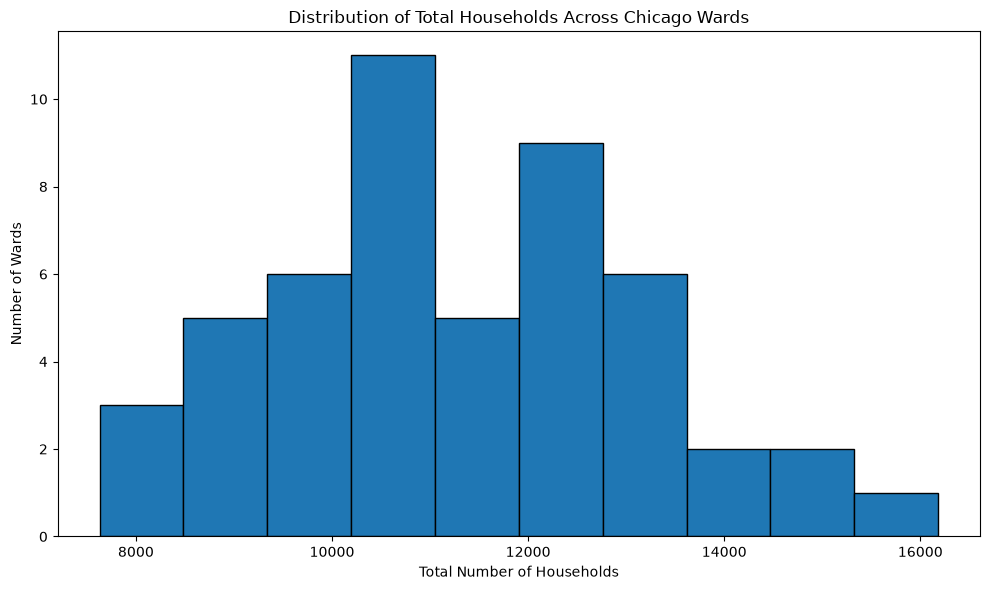

In [12]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["households_total"].to_numpy(),
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of Total Households Across Chicago Wards")
plt.xlabel("Total Number of Households")
plt.ylabel("Number of Wards")

plt.tight_layout()
plt.show()

### Plot 4: Distribution of Total Households Across Chicago Wards

The histogram shows how the total number of households varies across Chicago's 50 wards.

Most wards have approximately 9,000 to 13,500 households, with an average of around 11,317 households per ward.

The distribution is roughly bell-shaped with a slight right tail. A few wards have more than 14,000 households, while some have fewer than 9,000.

Overall, the number of households varies across wards, which is important when comparing crime patterns because wards with more households may naturally have more reported crimes.

# Part 4: Relationship Analysis

## Relationship Between Ward Income and Crime Counts

In [2]:
import polars as pl
# Load Chicago crime dataset
crimes_df = pl.read_csv(
    "../Crimes_-_2026_20260928.csv",
    infer_schema_length=10000,
    ignore_errors=True
)

print("Crime Dataset Shape:")
print(crimes_df.shape)

print("\nCrime Dataset Columns:")
print(crimes_df.columns)

print("\nFirst 5 Rows:")
print(crimes_df.head())

Crime Dataset Shape:
(167474, 22)

Crime Dataset Columns:
['ID', 'Case Number', 'Date', 'Block', 'IUCR', 'Primary Type', 'Description', 'Location Description', 'Arrest', 'Domestic', 'Beat', 'District', 'Ward', 'Community Area', 'FBI Code', 'X Coordinate', 'Y Coordinate', 'Year', 'Updated On', 'Latitude', 'Longitude', 'Location']

First 5 Rows:
shape: (5, 22)
┌──────────┬─────────────┬────────────────┬───────────────┬───┬───────────────┬───────────┬────────────┬───────────────┐
│ ID       ┆ Case Number ┆ Date           ┆ Block         ┆ … ┆ Updated On    ┆ Latitude  ┆ Longitude  ┆ Location      │
│ ---      ┆ ---         ┆ ---            ┆ ---           ┆   ┆ ---           ┆ ---       ┆ ---        ┆ ---           │
│ i64      ┆ str         ┆ str            ┆ str           ┆   ┆ str           ┆ f64       ┆ f64        ┆ str           │
╞══════════╪═════════════╪════════════════╪═══════════════╪═══╪═══════════════╪═══════════╪════════════╪═══════════════╡
│ 14335596 ┆ JK423038    ┆ 09/20/2

In [4]:
# Count crimes in Chicago's 50 wards
crime_counts = (
    crimes_df
    .filter(
        pl.col("Ward").is_between(1, 50)
    )
    .group_by("Ward")
    .agg(
        pl.len().alias("crime_count")
    )
    .sort("Ward")
)

print(crime_counts)

shape: (50, 2)
┌──────┬─────────────┐
│ Ward ┆ crime_count │
│ ---  ┆ ---         │
│ i64  ┆ u32         │
╞══════╪═════════════╡
│ 1    ┆ 2999        │
│ 2    ┆ 2582        │
│ 3    ┆ 4550        │
│ 4    ┆ 5472        │
│ 5    ┆ 4532        │
│ …    ┆ …           │
│ 46   ┆ 2903        │
│ 47   ┆ 1734        │
│ 48   ┆ 2118        │
│ 49   ┆ 2436        │
│ 50   ┆ 1673        │
└──────┴─────────────┘


In [5]:
# Load Chicago ward income dataset
income_df = pl.read_csv("../chicago-ward-income.csv")

# Check column names before joining
print("Income Dataset Columns:")
print(income_df.columns)

print("\nCrime Dataset Columns:")
print(crime_counts.columns)

Income Dataset Columns:
['ward', 'acs_year', 'households_under_25k', 'households_25k_to_50k', 'households_50k_to_75k', 'households_75k_to_125k', 'households_125k_plus', 'households_total', 'pct_households_125k_plus', 'median_household_income_est']

Crime Dataset Columns:
['Ward', 'crime_count']


In [6]:
# Join ward income with crime counts
combined_df = income_df.join(
    crime_counts,
    left_on="ward",
    right_on="Ward",
    how="inner"
)

# Keep the columns needed for our analysis
combined_df = combined_df.select(
    "ward",
    "median_household_income_est",
    "crime_count"
)

print("Combined Dataset Shape:")
print(combined_df.shape)

print("\nFirst 5 Rows:")
print(combined_df.head())

Combined Dataset Shape:
(50, 3)

First 5 Rows:
shape: (5, 3)
┌──────┬─────────────────────────────┬─────────────┐
│ ward ┆ median_household_income_est ┆ crime_count │
│ ---  ┆ ---                         ┆ ---         │
│ i64  ┆ i64                         ┆ u32         │
╞══════╪═════════════════════════════╪═════════════╡
│ 1    ┆ 148701                      ┆ 2999        │
│ 2    ┆ 162714                      ┆ 2582        │
│ 3    ┆ 101016                      ┆ 4550        │
│ 4    ┆ 109259                      ┆ 5472        │
│ 5    ┆ 81742                       ┆ 4532        │
└──────┴─────────────────────────────┴─────────────┘


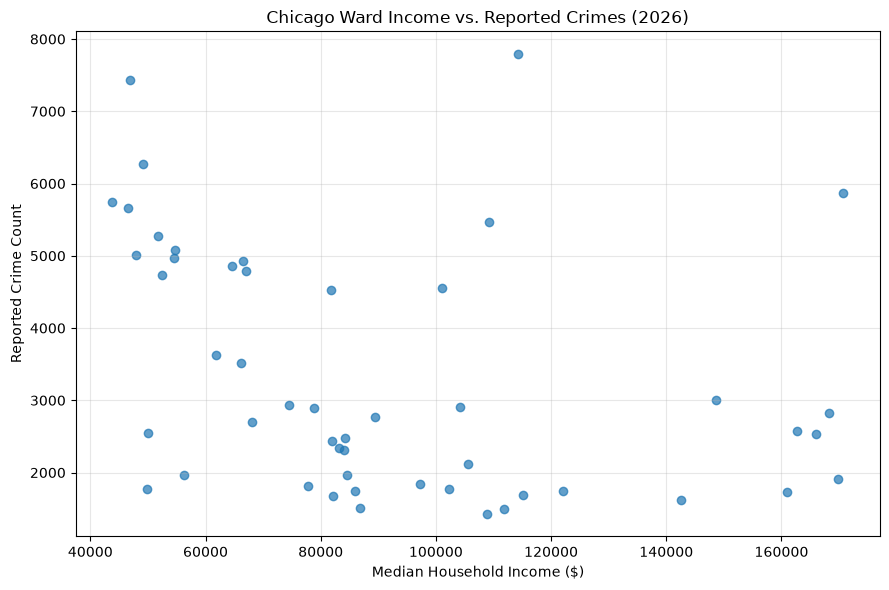

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    combined_df["median_household_income_est"],
    combined_df["crime_count"],
    alpha=0.7
)

plt.xlabel("Median Household Income ($)")
plt.ylabel("Reported Crime Count")
plt.title("Chicago Ward Income vs. Reported Crimes (2026)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Part 4: Observations

The scatter plot compares median household income with reported crime counts across Chicago's 50 wards.

The Pearson correlation coefficient is -0.34, indicating a weak-to-moderate negative relationship. This suggests that wards with higher median household incomes tend to have fewer reported crimes, although there are several exceptions.

The relationship is not strong, and income alone cannot explain differences in crime counts.

These findings do not establish causation. Crime counts are not adjusted for population, and the income estimates are from 2023 while the crime records are from 2026.

## Part 5: So What?

Our analysis found a weak-to-moderate negative correlation (-0.34) between median household income and reported crime counts across Chicago's 50 wards.

This finding is relevant to our research because differences in neighborhood income may be associated with differences in reported crime. When examining whether Flock cameras help reduce crime, we should consider other factors, such as income, rather than assuming that differences in crime counts are caused by camera presence.

However, our analysis does not directly measure the effectiveness of Flock cameras. Further analysis is needed to examine camera locations, crime rates, and changes in crime over time.

## Part 6: What's Next?

Our analysis found a weak-to-moderate negative relationship between median household income and reported crime counts across Chicago's 50 wards.

However, there are several limitations. The income data is from 2023, while the crime data is from part of 2026. We also used total reported crime counts rather than crime rates adjusted for population.

For future analysis, we could:

1. Compare Flock camera locations with crime patterns across Chicago wards.
2. Calculate crime rates using population data to make comparisons between wards more meaningful.
3. Examine crime trends before and after Flock camera installation, if installation dates are available.
4. Investigate whether neighborhood income is associated with camera placement.

Based on these findings, we could refine our research question to:

"How is Flock camera presence associated with reported crime patterns across Chicago neighborhoods, after considering differences in neighborhood income and population?"

This revised question would help us investigate the relationship between cameras and crime while considering other factors that may influence the results.